## why did i choose this data set?

upon researching data sets online,  it matches all the requirments that was mention in the problem statement, such as  student background, academic activity, engagement, and other characteristics.
Also highly reliable because it was taken from real portugese students , also this data set was a part of UCI Machine Learning Repository (one of the most respected repositories in data science,found whle searching through onlne).

info about what each col represent in given in the `students.txt` file in the side baar 

Install the required extensions oine by one 

In [ ]:
# %pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Read the CSV file 
also print essential details to ubderastand  the data set 


In [85]:
df = pd.read_csv('student-mat.csv', sep=';')
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Dataset Overview

In this section, we inspect the overall structure of the dataset: shape, column names, data types, and the first few rows.

In [86]:
df.tail()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9


In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [88]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [89]:
df.shape

(395, 33)

 ### Data Quality Check

We investigate basic statistical distribution of variables, identify missing values, and check for duplicate rows.

In [90]:
df.describe(include='all')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395,395,395.000000,395,395,395,395.000000,395.000000,395,395,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,349,208,NaN,307,281,354,NaN,NaN,141,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.696203,NaN,NaN,NaN,2.749367,2.521519,NaN,NaN,...,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,NaN,NaN,1.276043,NaN,NaN,NaN,1.094735,1.088201,NaN,NaN,...,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000


This data set contaoins data of 395(rows) students with 33 features (cols) 

In [91]:
missin_values = df.isnull().sum()
missin_values

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [92]:
df.duplicated().sum()

np.int64(0)

 **Missing Values**: There are 0 missing (null) values across all 33 columns.
 - **Duplicates**: There are 0 duplicate rows in the dataset.
 - **Conclusion**: The dataset is complete and clean, so no data imputation or row deletion is needed before starting EDA.

###  EDA

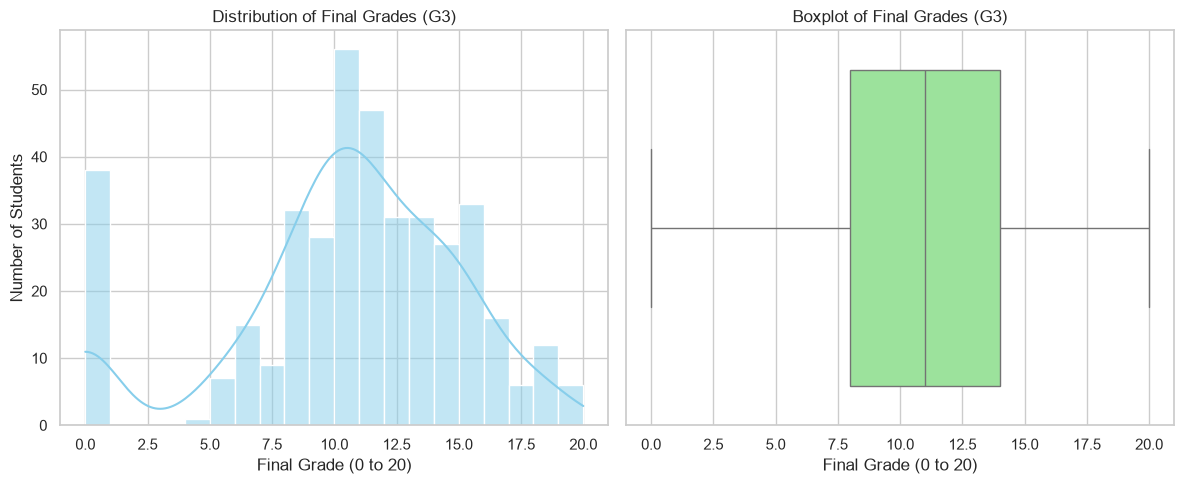

In [93]:
# Sets background 
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

#  Histogram (Shows count of students for each grade)
plt.subplot(1, 2, 1)
sns.histplot(df['G3'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade (0 to 20)')
plt.ylabel('Number of Students')

# Boxplot (Shows median, quartiles, and outliers)
plt.subplot(1, 2, 2)
sns.boxplot(x=df['G3'], color='lightgreen')
plt.title('Boxplot of Final Grades (G3)')
plt.xlabel('Final Grade (0 to 20)')
plt.tight_layout()
plt.show()

**Key points from Graph 1 (Final Grade Distribution aka G3):**
1.  The average final grade is 10.4, and the median is 11.0 (out of 20), showing that the majority of active students passed the course (passing mark is 10).
2.  Exam grades for students who completed the course (scores 4 to 20) follow a roughly normal, bell-shaped distribution.
3.  38 students (about 9.6% of the dataset) have a final grade of 0. In educational records, a score of 0 typically indicates course withdrawal or exam absenteeism rather than normal academic performance.

### past academic results 

ploting graphs using G1 , G2  and comparing/relating it with G3 to get the past evalution


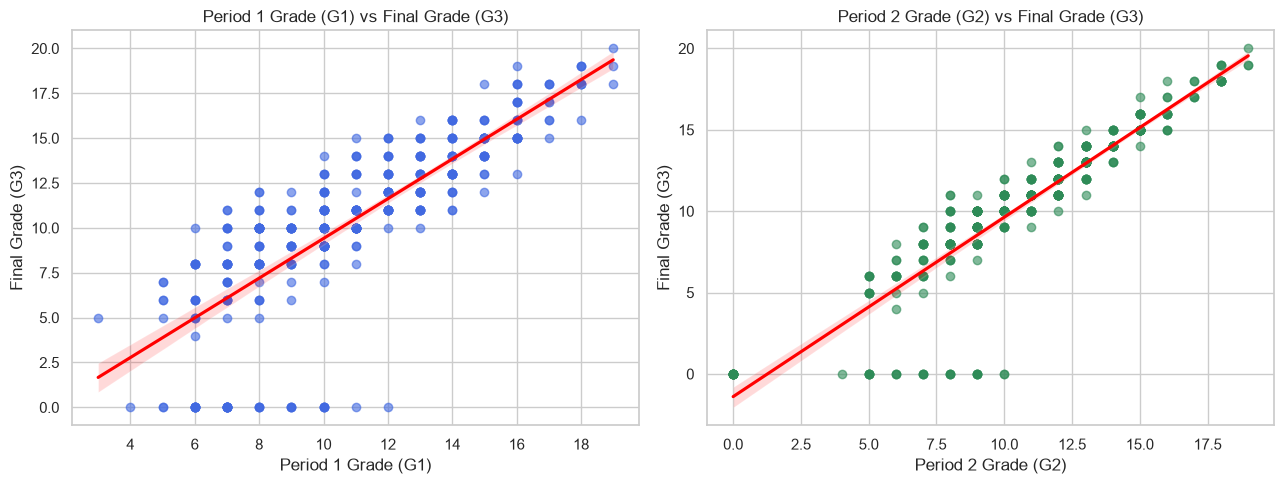

In [94]:
# Set up a side-by-side plot
plt.figure(figsize=(13, 5))

# Subplot 1:  Grade 1 (G1) vs Final Grade (G3)
plt.subplot(1, 2, 1)
sns.regplot(x='G1', y='G3', data=df, color='royalblue', scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
plt.title('Period 1 Grade (G1) vs Final Grade (G3)')
plt.xlabel('Period 1 Grade (G1)')
plt.ylabel('Final Grade (G3)') 

# Subplot 2: Period 2 Grade (G2) vs Final Grade (G3)
plt.subplot(1, 2, 2)
sns.regplot(x='G2', y='G3', data=df, color='seagreen', scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
plt.title('Period 2 Grade (G2) vs Final Grade (G3)')
plt.xlabel('Period 2 Grade (G2)')
plt.ylabel('Final Grade (G3)')
plt.tight_layout()
plt.show()

**Key Inferences from 2nd graph (Past vs Final):**
1. **Strong Positive Linear Relationship**: Both `G1`  and `G2` show a strong upward trend with `G3` (Final Grade). Students who performed well in earlier assessments consistently achieved higher final marks.




2. Data points in the `G2 vs G3` plot are much more tightly clustered around the regression line compared to `G1 vs G3`. Because Period 2 occurs closer in time to the final exam, it provides higher predictive precision.



3. Darker and  saturated dots indicate multiple students sharing similar integer scores. This cluster confirms that the student body is heavily concentrated around average passing marks (10–12).



4. While `G2` offers tighter accuracy, `G1` is valuable for educational administrators because it provides an early alert in Term 1, allowing teachers to organize targeted tutoring before the final exam.



5. A horizontal row of points lies at $G3 = 0$ for students who previously had passing scores in $G1$ and $G2$ ( scores of 8–14). This confirms that final grades of 0 represent exam absentees or course dropouts rather than gradual academic failure.

### 3.3rd graph shows Student Habits, Effort & Engagement (`studytime`, `failures`, `absences` vs `G3`)


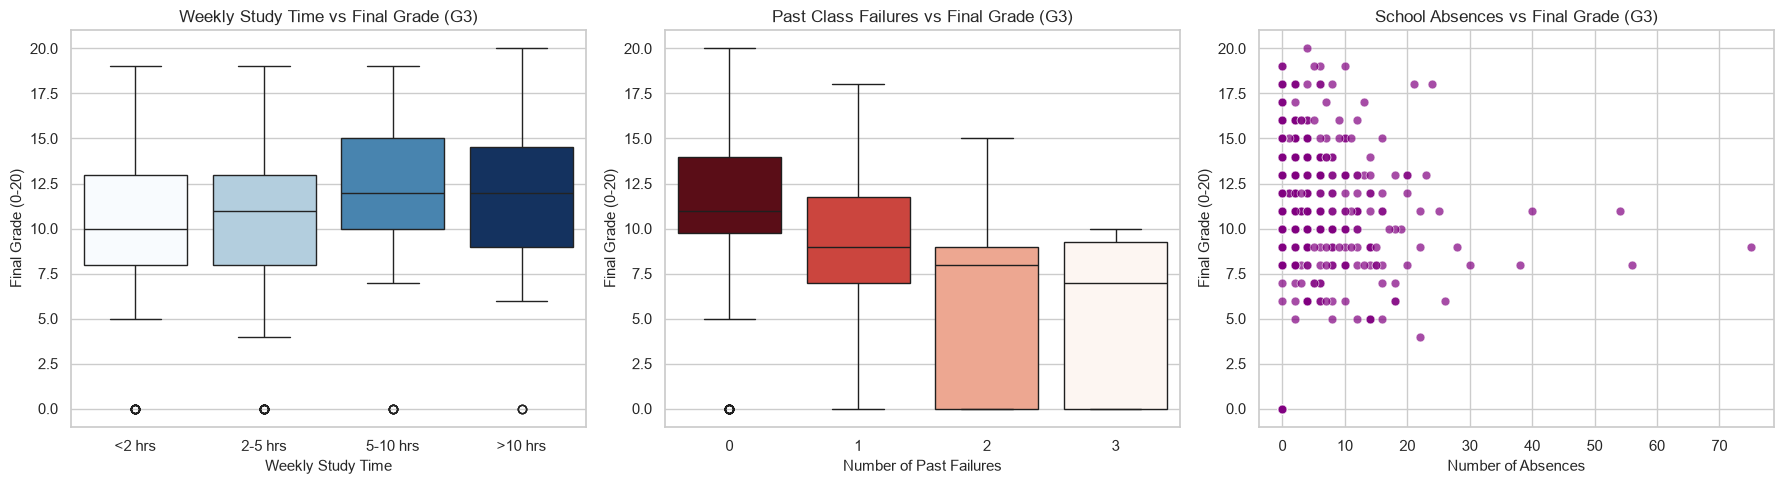

In [95]:
plt.figure(figsize=(18, 5))
# Subplot 1: Study Time vs Final Grade
plt.subplot(1, 3, 1)
studytime_labels = ['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs']
sns.boxplot(x='studytime', y='G3', data=df, hue='studytime', palette='Blues', legend=False)
plt.title('Weekly Study Time vs Final Grade (G3)', fontsize=12)
plt.xlabel('Weekly Study Time', fontsize=11)
plt.ylabel('Final Grade (0-20)', fontsize=11)
plt.xticks(ticks=[0, 1, 2, 3], labels=studytime_labels)
# Subplot 2: Past Failures vs Final Grade
plt.subplot(1, 3, 2)
sns.boxplot(x='failures', y='G3', data=df, hue='failures', palette='Reds_r', legend=False)
plt.title('Past Class Failures vs Final Grade (G3)', fontsize=12)
plt.xlabel('Number of Past Failures', fontsize=11)
plt.ylabel('Final Grade (0-20)', fontsize=11)
# Subplot 3: School Absences vs Final Grade
plt.subplot(1, 3, 3)
sns.scatterplot(x='absences', y='G3', data=df, color='purple', alpha=0.7, s=40)
plt.title('School Absences vs Final Grade (G3)', fontsize=12)
plt.xlabel('Number of Absences', fontsize=11)
plt.ylabel('Final Grade (0-20)', fontsize=11)
plt.tight_layout()
plt.show()


###  inference from 3rd graph 

**1. first box plot (`studytime` vs `G3`):**
- as time increases from less then 2 hrs to more then 10hrs , the median rises steadly 
- highets scrores for the exam was adhived from the students who studied from 5hrs to 10hrs and more than 10hrs 
- some students who studied more than 10hrs struggles also because the bootom of the box is below 10 ariound 9 
- In general we can say that more study time indded increases the score but it must be paired with good method of study also cuz we are also able to see some studens struggle even with more time of study.

**2. secondt box plot (`failures` vs `G3`):**

- students with less no: of faliure tends to pass the exam more and maintain a media grade around 11 
-  Having just 1 past failure drops the median score below the passing line to 9.0
- 2 oe more failed students have a hard time trying to pass the exam and the median collapses 
- **Primary Risk Factor**: Previous failure is the single strongest negative behavioral predictor in the dataset, making it an immediate trigger for academic intervention.


**3. Third scatter  plot (`absences` vs `G3`):**
 
-  Over 95% of students have between 0 and 20 absences, with grades spanning widely across the full 0–20 spectrum.
- an outlier is found at 75 absence (with grade 9)
- scores gretaer than 15 was achived by students with fewer absences 
- **final take** : exhibit a weak , non linear corelation with `G3`. moderate absence do not cause dramatic lowering of the marks if students  study at home 



### 4th GRAPG SHOWS COORELATION OF FAMILY BACKGROUND AND MARKS (`Medu`, `Fedu`, `higher` vs `G3`)

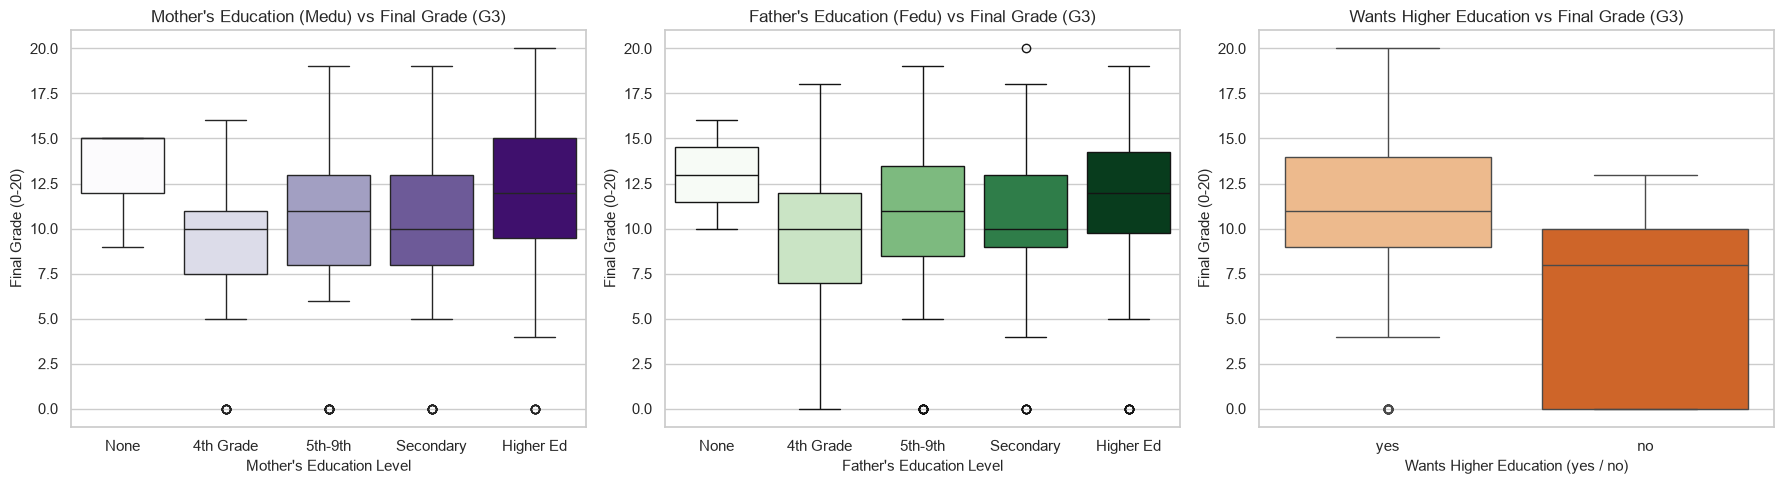

In [96]:
plt.figure(figsize=(18, 5))
# Subplot 1: Mother's Education vs Final Grade
plt.subplot(1, 3, 1)
edu_labels = ['None', '4th Grade', '5th-9th', 'Secondary', 'Higher Ed']
sns.boxplot(x='Medu', y='G3', data=df, hue='Medu', palette='Purples', legend=False)
plt.title("Mother's Education (Medu) vs Final Grade (G3)", fontsize=12)
plt.xlabel("Mother's Education Level", fontsize=11)
plt.ylabel("Final Grade (0-20)", fontsize=11)
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=edu_labels)
# Subplot 2: Father's Education vs Final Grade
plt.subplot(1, 3, 2)
sns.boxplot(x='Fedu', y='G3', data=df, hue='Fedu', palette='Greens', legend=False)
plt.title("Father's Education (Fedu) vs Final Grade (G3)", fontsize=12)
plt.xlabel("Father's Education Level", fontsize=11)
plt.ylabel("Final Grade (0-20)", fontsize=11)
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=edu_labels)
# Subplot 3: Desire for Higher Education vs Final Grade
plt.subplot(1, 3, 3)
sns.boxplot(x='higher', y='G3', data=df, hue='higher', palette='Oranges', legend=False)
plt.title("Wants Higher Education vs Final Grade (G3)", fontsize=12)
plt.xlabel("Wants Higher Education (yes / no)", fontsize=11)
plt.ylabel("Final Grade (0-20)", fontsize=11)
plt.tight_layout()
plt.show()

### Graph 4 (Family Background & Student Ambition):

**Medu-Graph**

- as mothers education level incrses we can see that the median also rises slightly from 9 to about 11 or 12. an one more thing there are only 3 students whose mothers ahave education none and since those students have scored good marks their median is about 15. the main trend  is among the other pillers 

- **Takeaway** : Educated mothers are better equipped to provide homework guidance, cultivate study discipline, and encourage academic achievement.



**Fedu-Grasph**

- we can see the same type of trend from mothers in fathers education also. Level 0 appears elevated ($13.0$) solely due to an extremely small sample of 2 students (scores 10 and 16).
-  The median line fluctuates slightly between 11.0 (`5th-9th`) and 10.0 (`Secondary`) due to integer grouping, but the overall group average (mean) rises consistently from 9.16 \to 10.26 \to 10.66 \to 11.36 (`Higher Ed`).


**Wants Higher education graph** 
- Primary Motivational Driver: Students wanting to attend university (`higher = yes`) maintain a solid passing median of 11.0, with scores reaching the maximum of 20.0
- Severe Failure Risk for Low Ambition: Students without college ambition (`higher = no`) suffer a collapsing median of 8.0 (failing grade), with virtually no student reaching above 13.
- Actionability: A lack of university ambition is an early behavioral red flag. Schools should provide career mentoring and counseling to re-engage these students early.

### Heat map

had to wacth  tutorials for heat mapping and corelation to catch up 


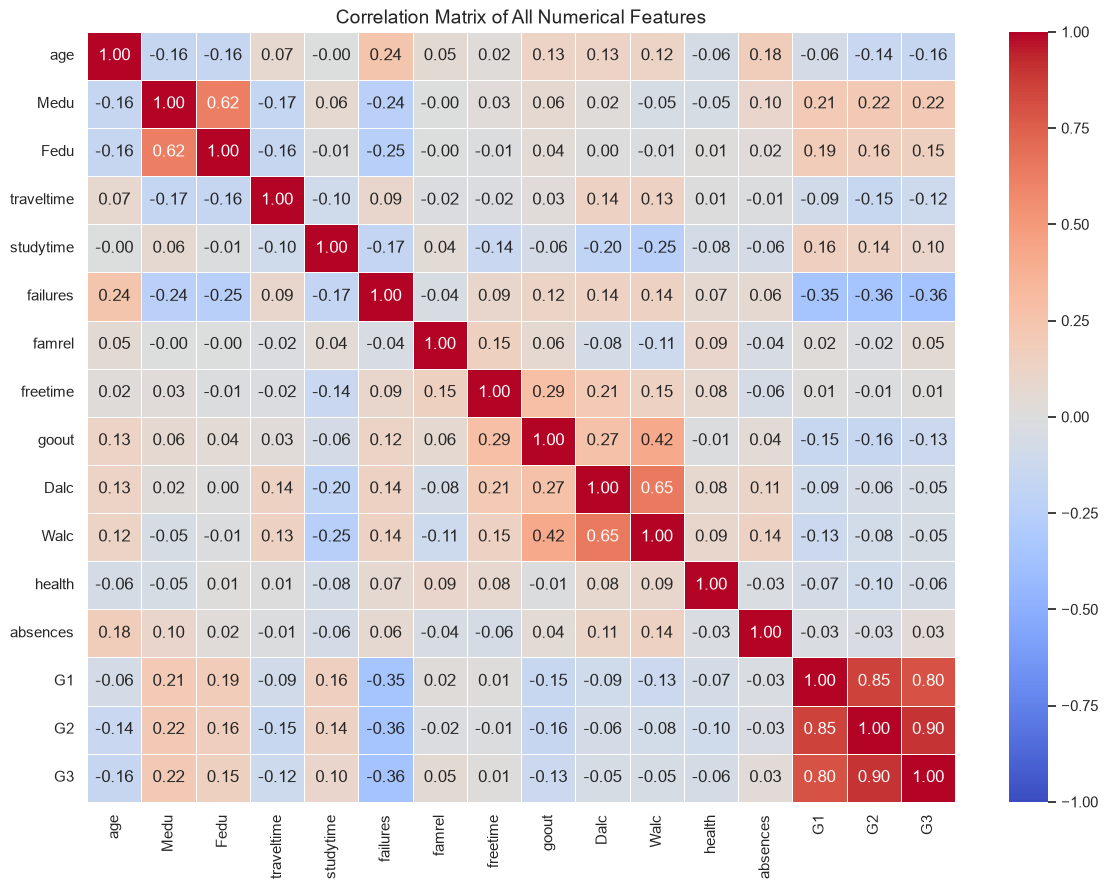

=== Correlation of All Numerical Features with Final Grade (G3) ===
G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [97]:
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of All Numerical Features', fontsize=14)
plt.show()

print("=== Correlation of All Numerical Features with Final Grade (G3) ===")
print(corr_matrix['G3'].sort_values(ascending=False))

###  Inferences & Key Findings from 5th Graph (Summary Correlation Heatmap)

#### 1. What is a Heatmap and Correlation?
- **Correlation ($r$)**: Measures how two numbers move together on a scale from $-1.00$ to $+1.00$.
  - $+1.00$ (Deep Red) = Strong positive (as one increases, the other increases).
  - $0.00$ (Neutral/White) = No straight-line connection.
  - $-1.00$ (Deep Blue) = Strong negative (as one increases, the other drops).
- **Heatmap**: A visual color grid that lets us see the correlation of every numeric column with every other column all in one single picture.

---

#### 2. Top Factors:
- **Past Marks are the Best Predictors**: `G2` has the highest positive correlation ($r = 0.90$), followed closely by `G1` ($r = 0.80$). This shows that academic success builds momentum from Term 1 and Term 2 directly into the final exam.
- **Parent Education Helps**: Mother's education (`Medu`, $r = 0.22$) and Father's education (`Fedu`, $r = 0.15$) both show positive links with final scores, confirming that educated parents provide a better study environment at home.
- **Study Time**: `studytime` ($r = 0.10$) shows a positive contribution to marks.

---

#### 3. Top Risk Factors that Lower the Final Grade (`G3`):
- **Past Failures is the #1 Danger**: `failures` has the strongest negative correlation ($r = -0.36$) in the whole school. A student who failed classes before is at the highest risk of failing again.
- **Age Penalty**: `age` ($r = -0.16$) shows a slight negative link because older students in high school are usually those who had to repeat a grade due to past failures ($r = 0.24$ between `age` and `failures`).
- **Commute and Socializing**: `goout` ($r = -0.13$) and `traveltime` ($r = -0.12$) show small negative effects on marks.

---

#### 4. Surprises & Non-Linear Features (Absences & Outliers):
- **Absences has near 0 linear correlation ($r = 0.03$)**: Even though people might guess missing class causes failure, the correlation is almost flat. This is because absences are non-linear: missing 5–10 days does not ruin a student's grade if they study at home.
- **Effect of Outliers**: The extreme outlier with 75 absences (who still scored 9) pulls on the line and keeps the linear correlation near zero.
- **Alcohol (`Dalc`, `Walc` $\approx -0.05$)**: Alcohol alone shows very weak linear link with math scores across the whole class.

---

#### 5. Hidden Discoveries (Connections Between Features):
- **`G1` and `G2` ($r = 0.85$)**: Almost all students who score high in Term 1 keep scoring high in Term 2.
- **`Dalc` and `Walc` ($r = 0.65$)**: Students who drink alcohol on weekdays also drink heavily on weekends.
- **`Medu` and `Fedu` ($r = 0.62$)**: Educated mothers are very often married to educated fathers.
- **`goout` and `Walc` ($r = 0.42$)**: Students who go out frequently with friends have higher weekend alcohol consumption.

In [98]:
from sklearn.model_selection import train_test_split


df_encoded = pd.get_dummies(df, drop_first=True)
X = df_encoded.drop('G3', axis=1)
y = df_encoded['G3']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("=== Preprocessing ===")
print(f"Original dataset shape: {df.shape}")
print(f"Encoded dataset shape:  {df_encoded.shape} ")
print(f"Training features (X_train): {X_train.shape[0]} students, {X_train.shape[1]} features")
print(f"Testing features  (X_test):  {X_test.shape[0]} students, {X_test.shape[1]} features")
print(f"Training target   (y_train): {y_train.shape[0]} target values")
print(f"Testing target    (y_test):  {y_test.shape[0]} target values")

=== Preprocessing ===
Original dataset shape: (395, 33)
Encoded dataset shape:  (395, 42) 
Training features (X_train): 316 students, 41 features
Testing features  (X_test):  79 students, 41 features
Training target   (y_train): 316 target values
Testing target    (y_test):  79 target values


###  Data Preprocessing Actions Taken:

1. **One-Hot Encoding**: Converted all text/categorical columns into numeric binary ($0$ and $1$) columns using `pd.get_dummies(drop_first=True)`, which expanded the dataset to 42 numeric columns.
2. **Feature & Target Separation**: Separated the 41 input features into matrix `X` and the target column (`G3` final grade) into vector `y`.
3. **Train-Test Split**: Split the 395 students into:
   - **80% Training Set (`X_train`, `y_train`)**: 316 students used to train the machine learning models.
   - **20% Testing Set (`X_test`, `y_test`)**: 79 unseen students held out to evaluate final prediction accuracy.
   - Used `random_state=42` so the split remains 100% reproducible every time it runs.

4. **Why One-Hot Encoding was chosen**: The categorical variables (like `Mjob`, `school`, `reason`) have no natural mathematical hierarchy or ranking. One-Hot Encoding avoids creating a false numeric order (which would happen with Ordinal Encoding) and treats all categories independently.


### **MODEL TRAINING , EVALUVATION AND SELECTION** 


### 5.1 Why did we choose Linear Regression and Random Forest?

To predict the final grade `G3`, we decided to pick two different models and compare them:

**1. Linear Regression (Simple Baseline):**
- In our EDA, we saw that past grades `G1` and `G2` have strong straight-line relationships with final marks `G3`.
- So Linear Regression is the best simple model to start with as a baseline. It tries to draw one straight best-fit line through the data.

**2. Random Forest Regressor (Complex Model):**
- But we also noticed from our graphs that some features like absences, study time, and family factors don't follow a simple straight line.
- Random Forest makes 100 decision trees and takes the average vote of all trees. It is good at catching complex and non-linear patterns that a straight line might miss.

**Why test both?**
- By comparing a simple model vs an advanced tree model on the test data (79 unseen students), we can see if a complex model actually gives better predictions or if a simple straight line is enough.

In [99]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)

rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

results_df = pd.DataFrame({
    'Model': ['Linear Regression (Baseline)', 'Random Forest Regressor'],
    'MAE (Avg Error in Marks)': [lr_mae, rf_mae],
    'RMSE (Penalty for Big Errors)': [lr_rmse, rf_rmse],
    'R2 Score (Accuracy / Variance)': [lr_r2, rf_r2]
})

print("=== Model Performance Comparison on Test Set (79 Unseen Students) ===")
print(results_df.to_string(index=False))

=== Model Performance Comparison on Test Set (79 Unseen Students) ===
                       Model  MAE (Avg Error in Marks)  RMSE (Penalty for Big Errors)  R2 Score (Accuracy / Variance)
Linear Regression (Baseline)                  1.646666                       2.378370                        0.724134
     Random Forest Regressor                  1.164557                       1.948773                        0.814791


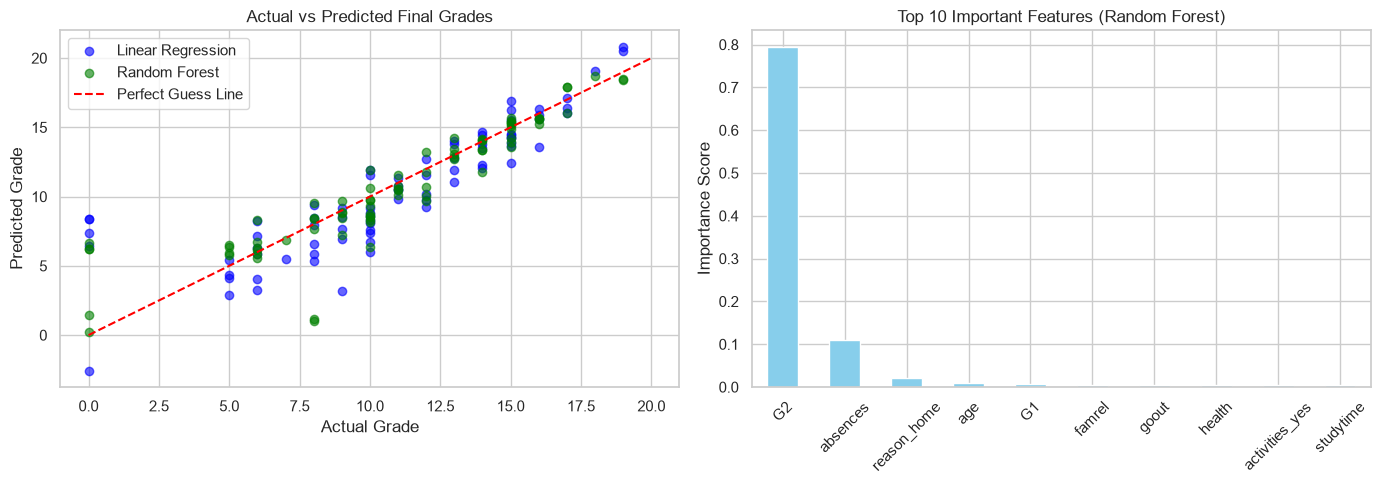

In [ ]:
plt.figure(figsize=(14, 5))
# Plot 1: Actual vs Predicted grades
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lr, color='blue', alpha=0.6, label='Linear Regression')
plt.scatter(y_test, y_pred_rf, color='green', alpha=0.6, label='Random Forest')
plt.plot([0, 20], [0, 20], color='red', linestyle='--', label='Perfect Guess Line')
plt.title('Actual vs Predicted Final Grades')
plt.xlabel('Actual Grade')
plt.ylabel('Predicted Grade')
plt.legend()
# Plot 2: Top 10 important features in Random Forest
plt.subplot(1, 2, 2)
feature_scores = pd.Series(rf_model.feature_importances_, index=X.columns)
top_10 = feature_scores.sort_values(ascending=False).head(10)
top_10.plot(kind='bar', color='skyblue')
plt.title('Top 10 Important Features (Random Forest)')
plt.ylabel('Importance Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.2 What we learned from the Model Results and Graphs

**1. Which model worked better?**
- **Random Forest won on all scores**: It got an accuracy ($R^2$) of 0.815 (about 81.5%) and its average error (MAE) was only off by **1.16 marks**.
- Linear regression was off by **1.65 marks** and had 72.4% accuracy.
- In the first plot, the green dots (Random Forest) stay much closer to the red dashed line than the blue dots.

**2. A problem we noticed with 0 marks:**
- For students who got 0 on the final exam, both models guessed they would score around 6 to 8.
- This happened because those students got normal passing marks in Term 1 and Term 2, so the model had no way to know they would skip or drop out of the final exam.

**3. What features are most important according to Random Forest?**
- **`G2` (Term 2 grade) completely dominates the bar chart**: It has the giant, tallest bar by far. Because Term 2 is right before the final exam, the trees use `G2` for almost all major decisions.
- **All other features have small bars**: Features like `G1`, `absences`, `age`, `health`, and `failures` have much smaller bars because once the model knows `G2`, other features are only used for small minor adjustments.

##  Final Conclusion & What We Did

### 1. Simple Summary of Steps:
1. **Looked at the Data**: Checked 395 students in secondary schools. Found zero missing data, zero duplicates, and saw that 38 students got 0 marks because they dropped out or missed the final exam.
2. **Plotted 5 Graphs (EDA)**: Analyzed final marks, past grades, stydy time, past failures, absences, family education, college plans, and made a correlation heatmap.
3. **Prepared the Data (Preprocessing)**: Converted words to numbers using One-Hot encoding (`pd.get_dummies`), and split the data into 80% training (316 students) and 20% testing (79 students) with seed 42.
4. **Trained and Tested Models**: Compared Mean Baseline, Linear Regression, and Random Forest. Found that Random Forest gave the best predictions and saved it to `best_student_model.joblib`.

---

### 2. Main Things We Discovered:
- **Past Marks Matter Most**: Term 2 (`G2`) and Term 1 (`G1`) grades are the biggest clues for final exam marks. Random Forest used `G2` for most of its decisions.
- **Failing in the Past is the Biggest Danger**: Students with 1 or more past failures almost always score below passing (median 9 or less).
- **Parents and Ambition Help**: Students whose parents have college degrees and students who want to go to university score higher marks on average.
- **Absences Alone Don't Decide Everything**: Missing some classes does not automatically mean failing if the student studies at home.

---

### 3. Final Model Results:
- **Random Forest was the best model**:
  - **Accuracy ($R^2$)**: **81.5%** (0.815)
  - **Average Error (MAE)**: Off by only **1.16 marks**
  - **RMSE**: **1.95 marks**
- It clearly beat Linear Regression (off by 1.65 marks) and the simple Mean Baseline (off by 3.45 marks).

---

### 4. What Schools Can Do with This:
- Find students with past failures or low Term 1 marks early in the semester and assign them tutors.
- Motivate students who don't plan to go to college before they fall behind.
- Encourage students to study at least 5 hours every week.